In [1]:
# Chit 3: Sign Language FNN: five actual and predicted labels
# Step 1: Import the libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

In [2]:
# Step 2: Load and prepare Sign Language MNIST
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

X_train = train_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
X_test = test_df.drop(columns="label").to_numpy(dtype="float32") / 255.0

encoder = LabelEncoder()
y_train = encoder.fit_transform(train_df["label"])
y_test = encoder.transform(test_df["label"])
class_names = [chr(int(label) + 65) for label in encoder.classes_]
image_shape = (28, 28, 1)

In [3]:
# Step 3: Flatten the images
X_train = X_train.reshape(-1, 28, 28).reshape(-1, 784)
X_test = X_test.reshape(-1, 28, 28).reshape(-1, 784)

In [4]:
# Step 4: Build the model
num_classes = len(class_names)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

In [5]:
# Step 5: Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
# Step 6: Prepare and run the model
model.fit(X_train, y_train, epochs=15, batch_size=128, verbose=0)

In [7]:
# Step 7: Predict test images
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

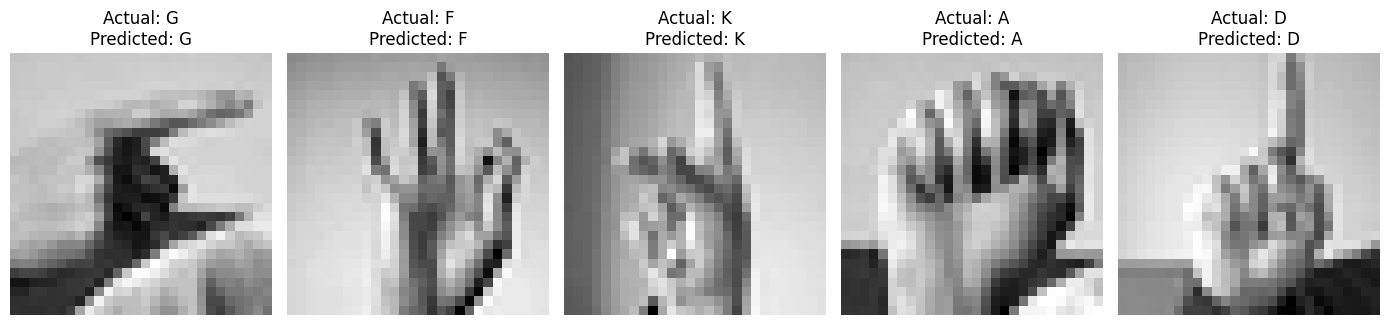

In [8]:
# Step 8: Show five examples
plt.figure(figsize=(14, 4))

for i in range(5):
    image = X_test[i].reshape(image_shape)

    plt.subplot(1, 5, i + 1)

    if image_shape[-1] == 1:
        plt.imshow(image.squeeze(), cmap="gray")
    else:
        plt.imshow(image)

    plt.title(
        f"Actual: {class_names[int(y_test[i])]}\n"
        f"Predicted: {class_names[int(y_pred[i])]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()